# Stock Triple-Barrier Classification · 05 Evaluation & Backtest

# Aim, Objective, and Motivation
- **Aim:** <u>test</u> whether the small validation edge survives on unseen data (2024-01 to 2026-10) and whether it is worth
  anything as a trading rule after costs.
- **Objective:** score every model once on the test period, pick a trading threshold on validation, backtest a long-only rule
  against buy-and-hold and random entries, and explain the LightGBM model with SHAP.
- **Motivation:** classification metrics a little above chance can still be worthless (or useful) once costs, overlapping trades and
  the market's own trend are included.

# Outlines
1. Load predictions & prices
2. Test-period classification metrics
3. Confusion matrix of the best validation model
4. Are the probabilities meaningful? (take-profit reliability)
5. Trading rule & threshold (validation)
6. Backtest on the test period
7. Is it better than luck? Random-entry benchmark
8. Explainability: SHAP for LightGBM
9. Summary & limitations

<!-- objective -->
## Objective

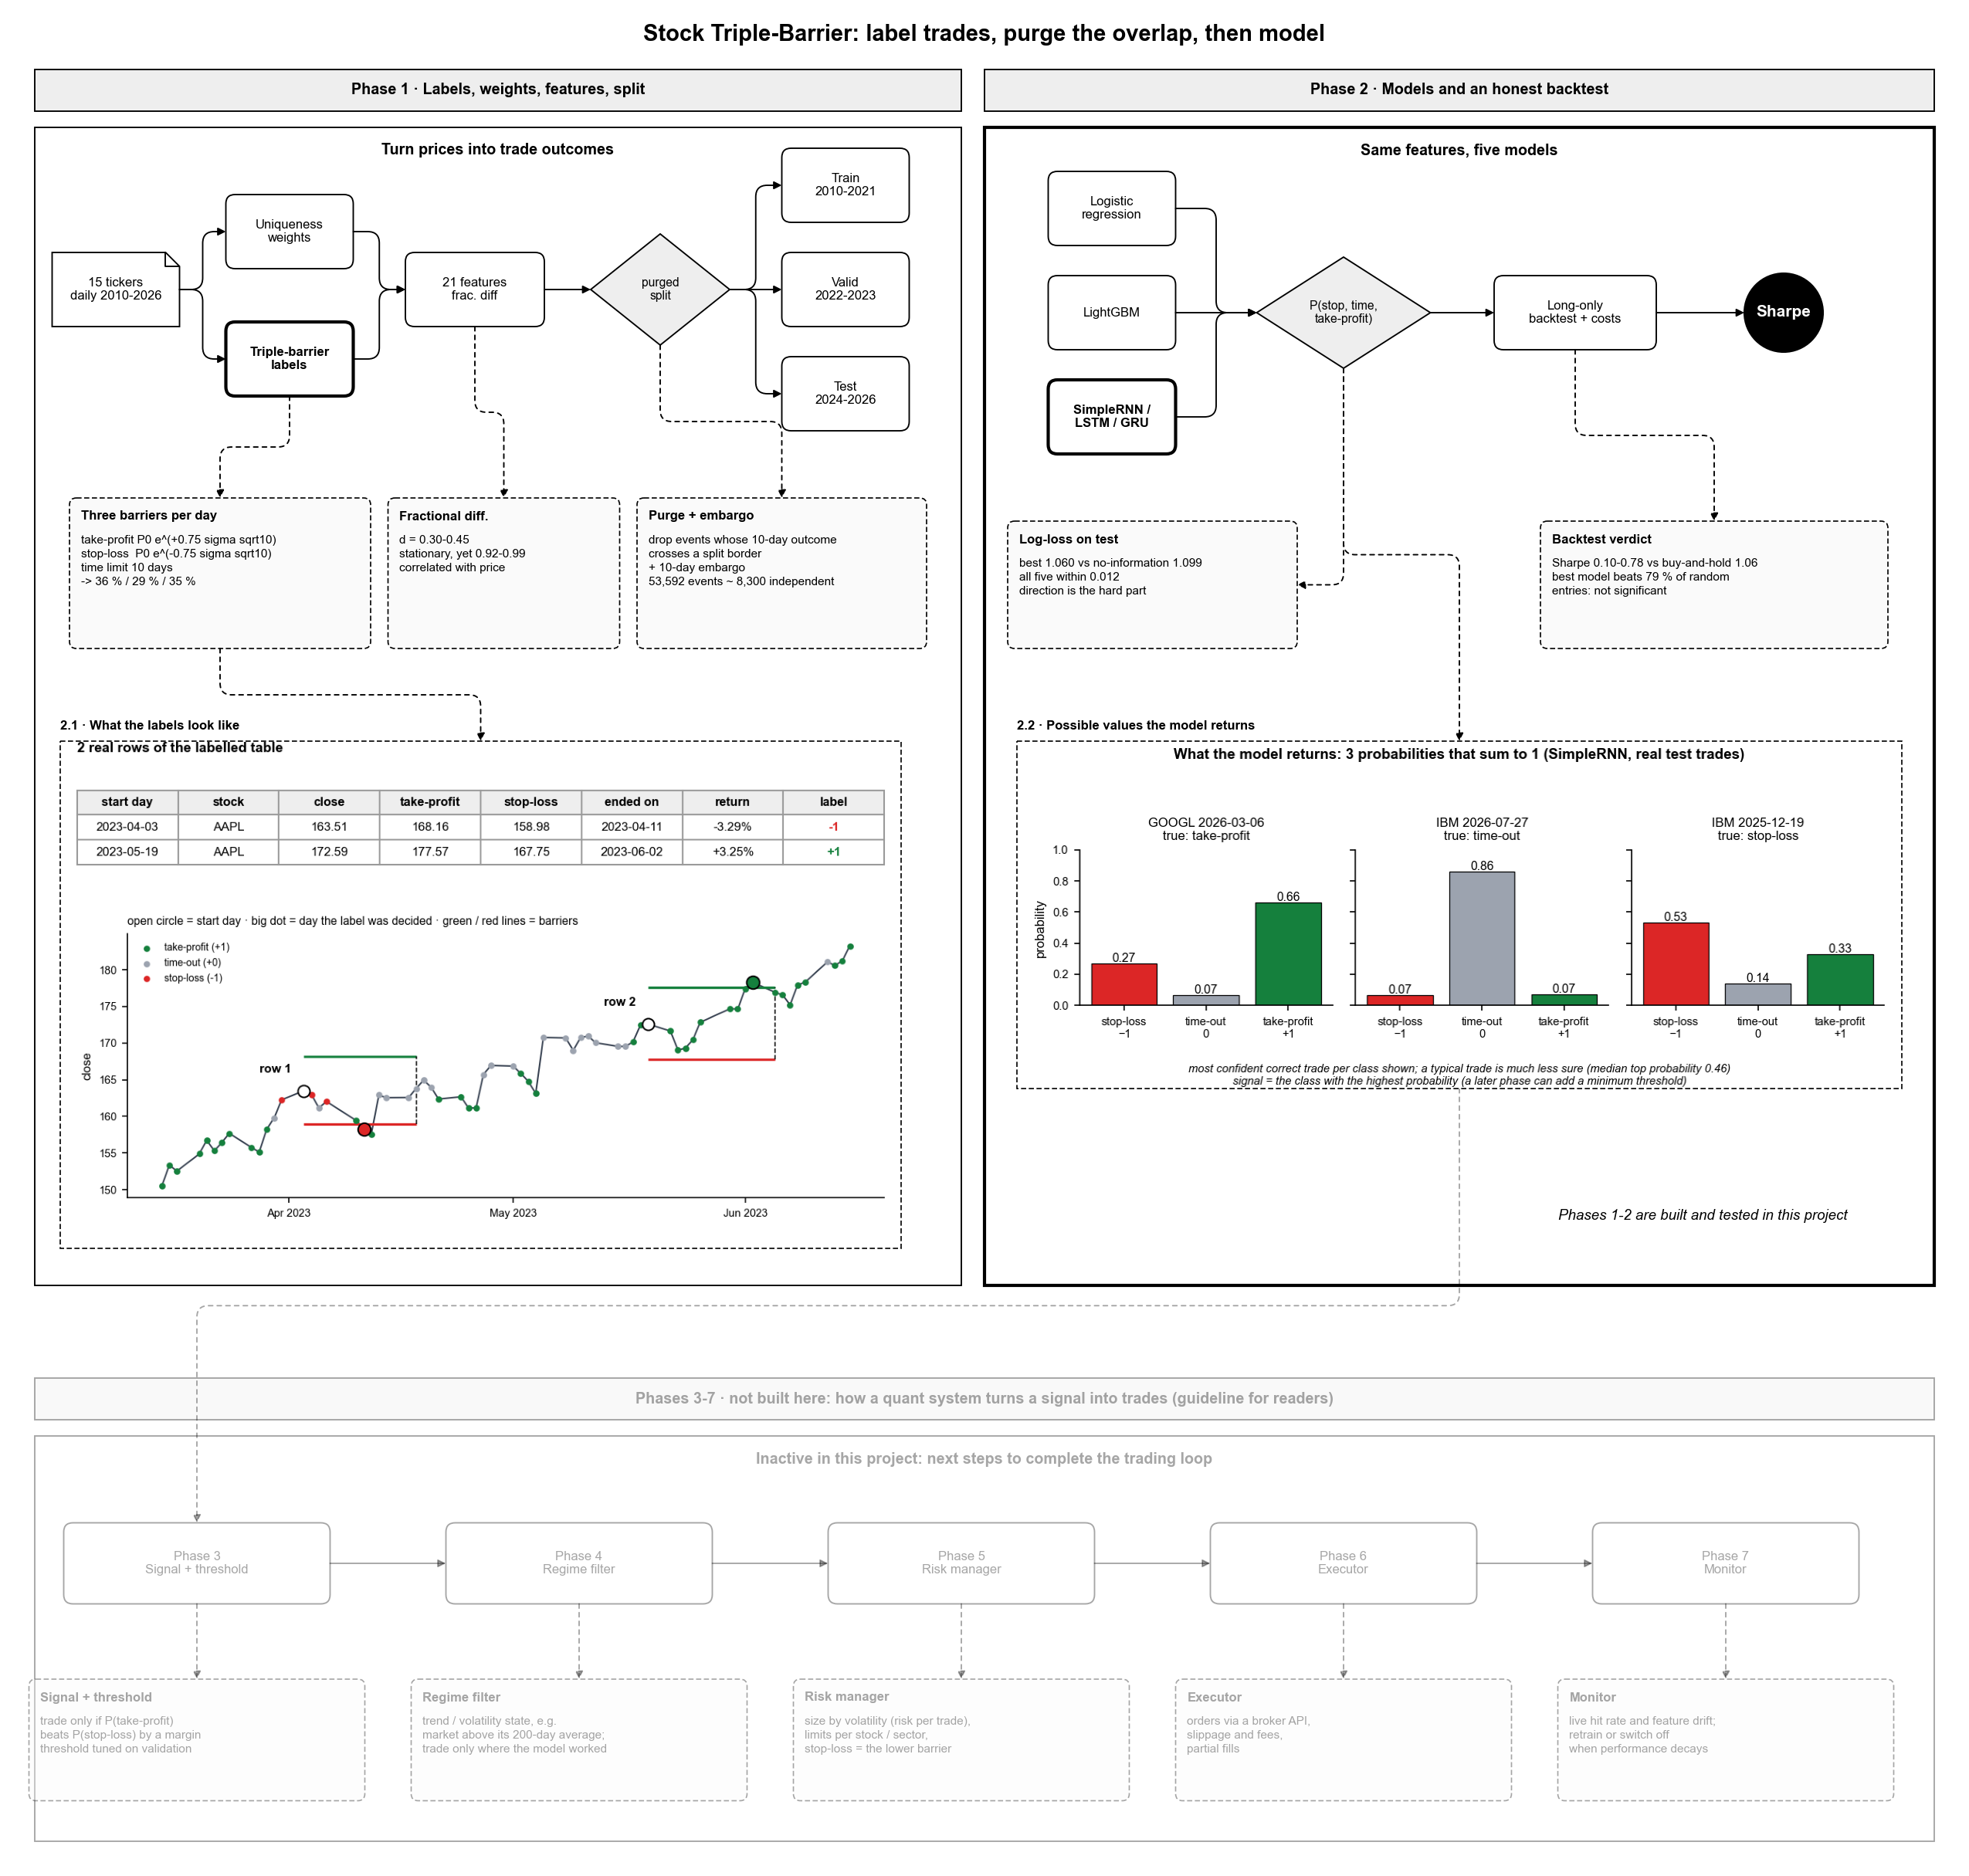

- **Problem** → most "stock prediction" notebooks predict tomorrow's price and report R² ≈ 0.99, yet copying yesterday's price scores the same: it looks smart and tells a trader nothing
- **Why this repo** → ask the question a trader actually has, *"if I buy today, do I hit my take-profit, my stop-loss, or run out of time?"*, and test it without leaking the future
- **Real-world use** → a sanity check before trusting any trading signal: label trades by outcome, purge overlapping samples, and compare against buy-and-hold and random entries

In [1]:
# ---------------------------------------------------------------- Imports
import sys
import json
import warnings
from pathlib import Path

sys.path.append(str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import shap
from sklearn.metrics import confusion_matrix

from src.config import TICKERS, CLASSES, LABEL_COLORS, PRICE_COLOR, MODELS_DIR, REPORTS_DIR, RANDOM_STATE, TEST_START
from src.data import download_prices, load_processed
from src.evaluate import LABELS, score, backtest_long, performance
from src.features import FEATURES
from src.plotting import set_style, savefig

# ---------------------------------------------------------------- Global constants
MODELS = ["Logistic Regression", "LightGBM", "SimpleRNN", "LSTM", "GRU"]
BEST_VALID_MODEL = "SimpleRNN"          # best validation log-loss in notebook 04
COST_BPS = 10                           # cost per side (commission + spread), basis points
THRESHOLD_GRID = np.round(np.arange(0.30, 0.66, 0.02), 2)   # P(take-profit) thresholds tried on validation
MIN_TRADES = 50                         # ignore thresholds giving fewer validation trades
N_RANDOM = 200                          # random-entry simulations
RELIABILITY_BINS = [0, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 1.0]
SHAP_SAMPLE = 3000
STRATEGY_COLORS = {"Buy & hold (same stocks)": "#9ca3af", "Random entries (median)": "black"}

set_style()

# [1/9] Load predictions & prices
> **Objective:** <u>load</u> the validation and test probabilities saved in notebook 04 (same rows for every model).

In [2]:
pred = load_processed("predictions")
prices = download_prices()
stock_prices = prices[prices.ticker.isin(TICKERS)]
valid, test = pred[pred.split == "valid"].reset_index(drop=True), pred[pred.split == "test"].reset_index(drop=True)
P = {s: {m: d[[f"{m}|p{l:+d}" for l in LABELS]].to_numpy() for m in MODELS + ["Prior (class frequencies)"]}
     for s, d in [("valid", valid), ("test", test)]}

In [3]:
print(f"valid: {len(valid):,} events ({valid.date.min().date()} to {valid.date.max().date()}) | "
      f"test: {len(test):,} events ({test.date.min().date()} to {test.date.max().date()})")

valid: 6,892 events (2022-01-03 to 2023-12-22) | test: 9,926 events (2024-01-02 to 2026-10-28)


# [2/9] Test-period classification metrics
> **Question:** does any model still beat the prior baseline on 2024–2026 data it has never seen?

In [4]:
w_test = test["uniqueness"] / test["uniqueness"].mean()
test_metrics = pd.DataFrame([score(test["label"].to_numpy(), P["test"][m], m, weights=w_test)
                             for m in ["Prior (class frequencies)"] + MODELS]).set_index("model")
test_metrics["log_loss_vs_prior"] = test_metrics["log_loss"] - test_metrics.loc["Prior (class frequencies)", "log_loss"]
valid_metrics = pd.read_csv(REPORTS_DIR / "validation_benchmark.csv", index_col=0)
compare = pd.DataFrame({"valid_log_loss": valid_metrics["log_loss"], "test_log_loss": test_metrics["log_loss"],
                        "valid_balanced_acc": valid_metrics["balanced_acc"], "test_balanced_acc": test_metrics["balanced_acc"]})

In [5]:
test_metrics.sort_values("log_loss").round(4)

,macro_f1,balanced_acc,log_loss,tp_precision,tp_recall,log_loss_vs_prior
model,,,,,,
SimpleRNN,0.3642,0.4094,1.0600,0.3828,0.5732,-0.0391
GRU,0.3686,0.4121,1.0636,0.3821,0.5900,-0.0355
Logistic Regression,0.3443,0.4045,1.0671,0.3784,0.6447,-0.0320
LightGBM,0.3358,0.3988,1.0714,0.3707,0.6689,-0.0276
LSTM,0.3924,0.4124,1.0717,0.3975,0.4611,-0.0273
Prior (class frequencies),0.1681,0.3333,1.0990,0.3371,1.0000,0.0000


In [6]:
compare.sort_values("test_log_loss").round(4)

,valid_log_loss,test_log_loss,valid_balanced_acc,test_balanced_acc
model,,,,
SimpleRNN,1.0803,1.0600,0.4142,0.4094
GRU,1.0865,1.0636,0.4105,0.4121
Logistic Regression,1.0896,1.0671,0.4000,0.4045
LightGBM,1.0841,1.0714,0.3982,0.3988
LSTM,1.0941,1.0717,0.3820,0.4124
Prior (class frequencies),1.1002,1.0990,0.3333,0.3333


**Answer:** yes, by a small margin. Every model beats the prior on test log-loss (SimpleRNN 1.060 vs 1.099, GRU 1.064,
logistic regression 1.067, LightGBM 1.071, LSTM 1.072) and reaches balanced accuracy 0.40–0.41 vs 0.33 for guessing.
The test edge is similar to validation, so it is not an artefact of model selection. SimpleRNN, chosen on validation,
is also best on test log-loss, but the gaps between models (≤ 0.012) are much smaller than the gap to the prior.

# [3/9] Confusion matrix of the best validation model
> **Objective:** <u>see</u> which outcomes the model confuses. Rows = true label, columns = predicted label (row-normalised).

In [7]:
pred_best = np.array(LABELS)[P["test"][BEST_VALID_MODEL].argmax(1)]
cm = confusion_matrix(test["label"], pred_best, labels=LABELS, normalize="true")
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.imshow(cm, cmap="Greys", vmin=0, vmax=1)
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if v > 0.5 else "black", fontsize=13)
names = [CLASSES[k] for k in LABELS]
ax.set(xticks=range(3), yticks=range(3), xticklabels=names, yticklabels=names, xlabel="predicted", ylabel="true",
       title=f"{BEST_VALID_MODEL}: test confusion matrix")
ax.grid(False)
savefig(fig, "05_confusion")
plt.close(fig)

In [8]:
pd.Series(pred_best).map(CLASSES).value_counts(normalize=True).round(3).rename("share of test predictions")

take-profit    0.505
time-out       0.441
stop-loss      0.055
Name: share of test predictions, dtype: float64

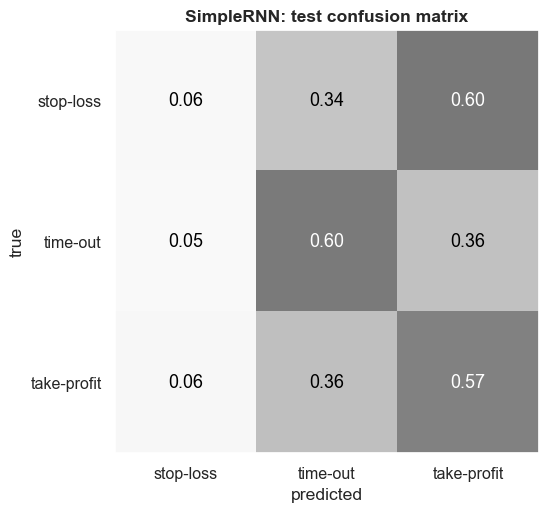

In [9]:
fig

**Answer:** the model separates **"will the price move enough to hit a barrier?"** much better than **"which way?"**:
60 % of time-outs are recognised, but true stop-losses are predicted as take-profit 60 % of the time — about as often as
true take-profits (57 %). It predicts stop-loss for only 5.5 % of test days. This matches the features: volatility features
carry most of the signal (notebook 03) and direction is close to unpredictable (notebook 01).

# [4/9] Are the probabilities meaningful? (take-profit reliability)
> **Question:** when a model gives a higher P(take-profit), does take-profit really happen more often?
> A useful model shows an **increasing** observed rate across probability bins.

In [10]:
rel_rows = []
for m in ["LightGBM", BEST_VALID_MODEL]:
    p_tp = P["test"][m][:, 2]
    g = pd.DataFrame({"p": p_tp, "tp": test["label"].eq(1)}).groupby(pd.cut(p_tp, RELIABILITY_BINS), observed=True)
    r = g.agg(events=("tp", "size"), mean_predicted=("p", "mean"), observed_tp_rate=("tp", "mean")).reset_index()
    r["model"] = m
    rel_rows.append(r)
reliability = pd.concat(rel_rows)

fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.plot([0.2, 0.7], [0.2, 0.7], ls="--", c="grey", label="perfect")
for m, c in [("LightGBM", PRICE_COLOR), (BEST_VALID_MODEL, "#dc2626")]:
    r = reliability[(reliability.model == m) & (reliability.events >= 30)]
    ax.plot(r.mean_predicted, r.observed_tp_rate, marker="o", color=c, label=m)
ax.axhline(test["label"].eq(1).mean(), color="black", lw=0.8, ls=":", label="test take-profit rate")
ax.set(xlabel="predicted P(take-profit)", ylabel="observed take-profit rate", title="Take-profit reliability (test)")
ax.legend()
savefig(fig, "05_reliability")
plt.close(fig)

In [11]:
reliability.round(3)

,index,events,mean_predicted,observed_tp_rate,model
0,"(0.0, 0.3]",1193,0.276,0.239,LightGBM
1,"(0.3, 0.35]",2177,0.328,0.301,LightGBM
2,"(0.35, 0.4]",3412,0.378,0.340,LightGBM
3,"(0.4, 0.45]",2601,0.419,0.384,LightGBM
4,"(0.45, 0.5]",433,0.467,0.425,LightGBM
5,"(0.5, 0.55]",95,0.523,0.537,LightGBM
6,"(0.55, 0.6]",15,0.562,0.800,LightGBM
0,"(0.0, 0.3]",2922,0.222,0.243,SimpleRNN
1,"(0.3, 0.35]",1298,0.326,0.326,SimpleRNN
2,"(0.35, 0.4]",1516,0.375,0.358,SimpleRNN


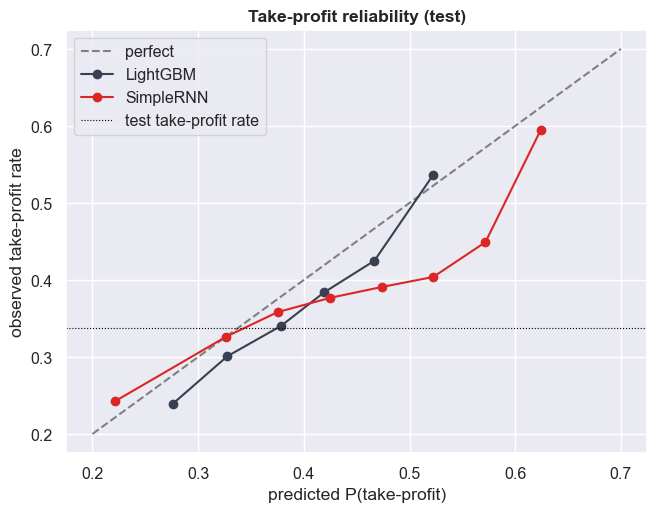

In [12]:
fig

**Answer:** partly. For both models the observed take-profit rate **rises** with the predicted probability (LightGBM: 24 % in the
lowest bin to 54 % at 0.50–0.55; SimpleRNN: 24 % to 60 % above 0.60), so the ranking carries information. SimpleRNN is
over-confident in the middle (predicted 0.52, observed 0.40), and LightGBM is slightly over-confident everywhere.

# [5/9] Trading rule & threshold (validation)
> **Rule (long-only):** on day $t_0$, if $P(\text{take-profit}) \ge \tau$ and the stock is not already held, buy at the close and sell
> at the close of $t_1$ (take-profit, stop-loss or day 10). One position per stock; capital split equally across the 14 stocks;
> idle capital earns 0. Cost: 10 bp on entry and on exit.
>
> **Metrics:** Sharpe $= \frac{\bar r}{\sigma_r}\sqrt{252}$ (daily returns, no risk-free rate), CAGR, maximum drawdown
> $= \min_t \left(\frac{E_t}{\max_{s \le t} E_s} - 1\right)$.
>
> $\tau$ is chosen per model to maximise the **validation** Sharpe (at least 50 trades), then frozen for the test period.

In [13]:
def portfolio(events, signal, period_prices):
    daily, trades = backtest_long(events, signal, period_prices, COST_BPS)
    simple = (np.exp(daily) - 1).reindex(columns=TICKERS).fillna(0).mean(axis=1)   # equal capital per stock
    return np.log1p(simple), trades


def period_slice(events):
    start, end = events.date.min(), events.t1.max()
    return stock_prices[(stock_prices.date >= start - pd.Timedelta(days=5)) & (stock_prices.date <= end)], start, end


valid_prices, v_start, v_end = period_slice(valid)
tau_rows = []
for m in MODELS:
    p_tp = pd.Series(P["valid"][m][:, 2])
    for tau in THRESHOLD_GRID:
        sig = p_tp >= tau
        if sig.sum() < MIN_TRADES:
            continue
        r, trades = portfolio(valid, sig, valid_prices)
        r = r[(r.index > v_start) & (r.index <= v_end)]
        tau_rows.append({"model": m, "tau": tau, "signals": int(sig.sum()), "trades": len(trades), **performance(r)})
tau_table = pd.DataFrame(tau_rows)
best_tau = tau_table.loc[tau_table.groupby("model")["sharpe"].idxmax()].set_index("model")

In [14]:
best_tau[["tau", "signals", "trades", "sharpe", "cagr", "max_drawdown"]].round(3)

,tau,signals,trades,sharpe,cagr,max_drawdown
model,,,,,,
GRU,0.54,378,118,1.537,0.113,-0.030
LSTM,0.50,864,213,0.972,0.105,-0.105
LightGBM,0.46,394,163,0.938,0.082,-0.072
Logistic Regression,0.48,216,99,0.791,0.044,-0.039
SimpleRNN,0.58,225,82,0.894,0.049,-0.025


**Answer:** the best validation thresholds lie between 0.46 and 0.58. Choosing $\tau$ by maximising Sharpe over a grid on one
two-year period is itself a form of overfitting, which the test period will reveal.

# [6/9] Backtest on the test period
> **Question:** with thresholds frozen from validation, does the rule beat buying and holding the same 14 stocks?

In [15]:
test_prices, t_start, t_end = period_slice(test)
close = test_prices.pivot(index="date", columns="ticker", values="close")
bh = np.log1p((close.pct_change()).reindex(columns=TICKERS).mean(axis=1))      # equal-weight, daily rebalanced
bh = bh[(bh.index > t_start) & (bh.index <= t_end)]

curves, perf_rows, trade_stats = {"Buy & hold (same stocks)": bh}, [], []
perf_rows.append({"strategy": "Buy & hold (same stocks)", **performance(bh), "exposure": 1.0, "trades": np.nan})
for m in MODELS:
    sig = pd.Series(P["test"][m][:, 2] >= best_tau.loc[m, "tau"])
    r, trades = portfolio(test, sig, test_prices)
    r = r[(r.index > t_start) & (r.index <= t_end)]
    curves[m] = r
    exposure = (r != 0).mean()
    perf_rows.append({"strategy": m, **performance(r), "exposure": exposure, "trades": len(trades)})
    trade_stats.append({"model": m, "trades": len(trades), "take_profit_share": (trades.label == 1).mean(),
                        "stop_loss_share": (trades.label == -1).mean(), "mean_trade_return_%": trades.ret.mean() * 100})
perf = pd.DataFrame(perf_rows).set_index("strategy")
trade_stats = pd.DataFrame(trade_stats).set_index("model")
base_tp_rate = test.drop_duplicates(["date", "ticker"])["label"].eq(1).mean()

In [16]:
perf.round(3)

,total_return,cagr,ann_vol,sharpe,max_drawdown,exposure,trades
strategy,,,,,,,
Buy & hold (same stocks),0.971,0.269,0.255,1.060,-0.284,1.000,NaN
Logistic Regression,0.115,0.039,0.052,0.756,-0.050,0.585,149.0
LightGBM,0.057,0.019,0.059,0.358,-0.098,0.479,144.0
SimpleRNN,0.096,0.033,0.052,0.643,-0.031,0.387,90.0
LSTM,0.208,0.069,0.090,0.777,-0.065,0.705,201.0
GRU,0.012,0.004,0.063,0.100,-0.061,0.540,156.0


In [17]:
print(f"take-profit share of ALL test events (base rate): {base_tp_rate:.3f}")
trade_stats.round(3)

take-profit share of ALL test events (base rate): 0.337


,trades,take_profit_share,stop_loss_share,mean_trade_return_%
model,,,,
Logistic Regression,149,0.497,0.322,0.851
LightGBM,144,0.451,0.354,0.370
SimpleRNN,90,0.511,0.311,1.286
LSTM,201,0.453,0.333,1.125
GRU,156,0.436,0.372,-0.114


**Answer:** no model beats buy-and-hold. Holding the 14 stocks returned 97 % (CAGR 27 %, Sharpe 1.06, max drawdown −28 %), while
the rules returned 1–21 % (Sharpe 0.10–0.78).

(!) Total returns are not a fair comparison: each stock gets 1/14 of the capital and is held only after a signal, so on average just
**5–11 % of the capital is invested** (the `exposure` column counts days with at least one open position, 39–71 %). Sharpe ratio
and drawdown ignore how much capital is used, and on Sharpe every rule is still below buy-and-hold (best: LSTM 0.78, logistic
regression 0.76, SimpleRNN 0.64 vs 1.06). The small drawdowns (−3 % to −10 %) mostly reflect the idle cash.

The signals do select better trades than average: 44–51 % of the rules' trades hit take-profit, against 34 % of all test events.
The validation-optimal thresholds did not carry over well (GRU: validation Sharpe 1.54, test 0.10).

# [7/9] Is it better than luck? Random-entry benchmark
> **Method:** for each model, enter on **random** days with the same number of signals per stock, using the same rule and costs,
> 200 times. If the model's Sharpe is not clearly above most random runs, its signals add nothing beyond being in the market.

In [18]:
rng = np.random.default_rng(RANDOM_STATE)
ref_model = BEST_VALID_MODEL
ref_sig = pd.Series(P["test"][ref_model][:, 2] >= best_tau.loc[ref_model, "tau"])
per_ticker_n = ref_sig.groupby(test["ticker"]).sum()
random_sharpes, random_curves = [], []
for _ in range(N_RANDOM):
    sig = pd.Series(False, index=test.index)
    for t, n in per_ticker_n.items():
        idx = test.index[test.ticker == t]
        sig[rng.choice(idx, int(n), replace=False)] = True
    r, _ = portfolio(test, sig, test_prices)
    r = r[(r.index > t_start) & (r.index <= t_end)]
    random_sharpes.append(performance(r)["sharpe"])
    random_curves.append(r.cumsum())
random_sharpes = np.array(random_sharpes)
model_sharpe = perf.loc[ref_model, "sharpe"]
percentile = (random_sharpes < model_sharpe).mean() * 100
curves["Random entries (median)"] = pd.concat(random_curves, axis=1).median(axis=1).diff().fillna(0)

fig, axes = plt.subplots(1, 2, figsize=(18, 5.2), gridspec_kw={"width_ratios": [1.6, 1]})
for name, r in curves.items():
    color = STRATEGY_COLORS.get(name)
    lw = 2.5 if name in (ref_model, "Buy & hold (same stocks)") else 1.2
    axes[0].plot(np.exp(r.cumsum()), label=name, color=color, lw=lw)
axes[0].set(title="Growth of $1 on the test period (after costs)", ylabel="equity")
axes[0].legend(fontsize=9)
axes[1].hist(random_sharpes, bins=30, color="#9ca3af")
axes[1].axvline(model_sharpe, color="#dc2626", lw=2.5, label=f"{ref_model}: {model_sharpe:.2f}")
axes[1].set(title=f"Sharpe of {N_RANDOM} random-entry runs", xlabel="Sharpe")
axes[1].legend()
savefig(fig, "05_backtest")
plt.close(fig)

In [19]:
print(f"{ref_model} Sharpe {model_sharpe:.2f} beats {percentile:.0f} % of random-entry runs "
      f"(random median {np.median(random_sharpes):.2f}, 5-95 % range {np.percentile(random_sharpes, 5):.2f} to "
      f"{np.percentile(random_sharpes, 95):.2f})")

SimpleRNN Sharpe 0.64 beats 79 % of random-entry runs (random median 0.27, 5-95 % range -0.51 to 0.92)


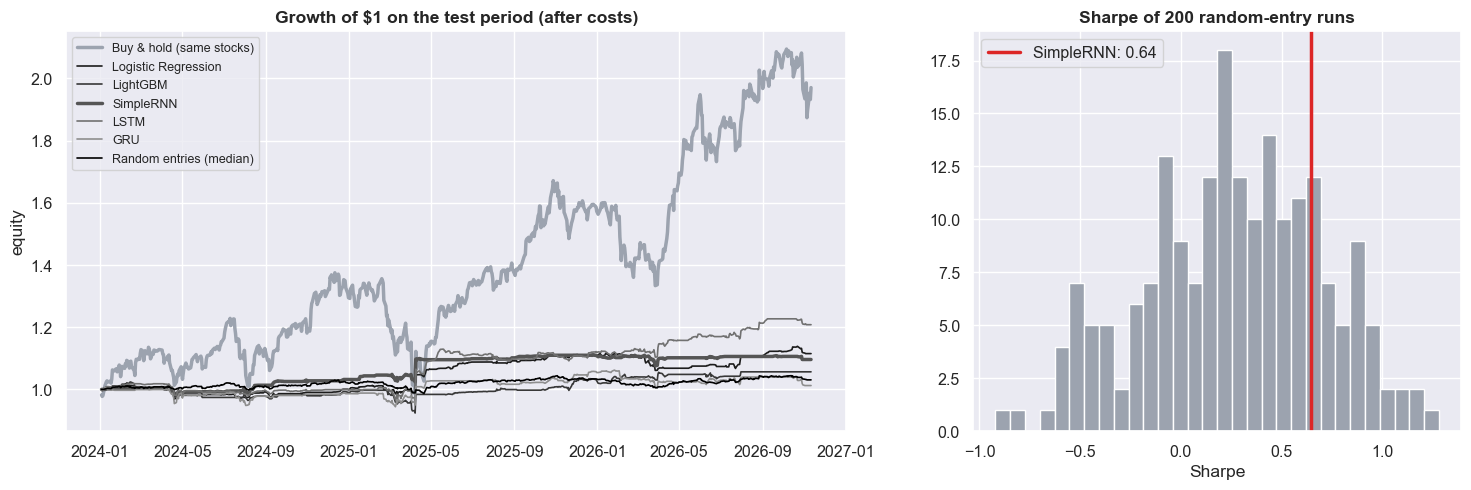

In [20]:
fig

**Answer:** not convincingly. SimpleRNN's Sharpe of 0.64 beats 79 % of random-entry runs with the same number of trades per stock
(random median 0.27). That is better than typical luck but well inside the random range (5–95 %: −0.51 to 0.92), so this test
cannot distinguish the signal from chance.

# [8/9] Explainability: SHAP for LightGBM
> **Question:** which features push the LightGBM model towards **take-profit**?
> SHAP splits each prediction (log-odds of the class) into feature contributions $f(x) = \phi_0 + \sum_j \phi_j$.

In [21]:
lgbm = joblib.load(MODELS_DIR / "lightgbm.joblib")
dataset = load_processed("dataset")
prep = json.load(open(REPORTS_DIR / "preprocessing.json"))
X_test = dataset[dataset.split == "test"][FEATURES]
X_test = np.clip((X_test - prep["scaler_mean"]) / prep["scaler_scale"], -prep["clip"], prep["clip"]).astype(np.float32)
X_shap = X_test.sample(SHAP_SAMPLE, random_state=RANDOM_STATE)
explanation = shap.TreeExplainer(lgbm)(X_shap)
tp_values = explanation[:, :, 2]                       # class index 2 = take-profit
importance = pd.Series(np.abs(tp_values.values).mean(0), index=FEATURES).sort_values(ascending=False)

plt.figure(figsize=(9, 7))
shap.plots.beeswarm(tp_values, max_display=15, show=False, plot_size=None)
plt.title("SHAP values for take-profit (LightGBM, test sample)")
fig_shap = plt.gcf()
savefig(fig_shap, "05_shap_take_profit")
plt.close(fig_shap)

In [22]:
importance.round(4).head(10)

vol_21            0.0850
ffd_close         0.0405
mkt_ret_5         0.0220
atr_14            0.0211
vol_ratio_5_21    0.0192
dist_sma_200      0.0191
mkt_vol_21        0.0159
bb_width          0.0121
bb_pctb           0.0076
rsi_14            0.0056
dtype: float64

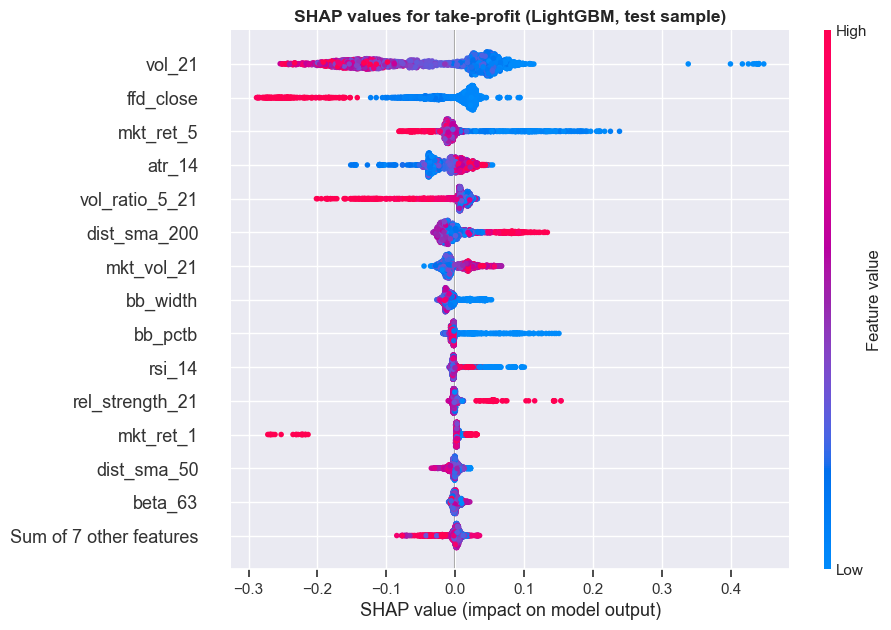

In [23]:
fig_shap

**Answer:** `vol_21` dominates by far (mean |SHAP| 0.085, twice the next feature), followed by `ffd_close` (the fractionally
differenced price), `mkt_ret_5`, `atr_14` and `vol_ratio_5_21`. Mostly volatility and market context, very little momentum —
consistent with the confusion matrix: the model mainly predicts *how much* a stock will move.

# [9/9] Summary & limitations

In [24]:
summary = {
    "test_log_loss": test_metrics["log_loss"].round(4).to_dict(),
    "test_balanced_acc": test_metrics["balanced_acc"].round(4).to_dict(),
    "backtest": perf[["sharpe", "cagr", "max_drawdown", "exposure"]].round(4).to_dict(orient="index"),
    "random_entry_percentile_of_" + ref_model: round(float(percentile), 1),
    "thresholds": best_tau["tau"].to_dict(),
}
json.dump(summary, open(REPORTS_DIR / "test_results.json", "w"), indent=2, default=float)

In [25]:
pd.Series({k: v for k, v in summary.items() if not isinstance(v, dict)})

random_entry_percentile_of_SimpleRNN    79.0
dtype: float64

**Findings**
- Triple-barrier outcomes are predictable **slightly** better than chance on unseen 2024–2026 data (log-loss 1.060 vs 1.099,
  balanced accuracy 0.41 vs 0.33), and the edge held from validation to test.
- The models mainly predict **whether** a stock will move enough to hit a barrier, not the direction.
- The recurrent networks were not clearly better than logistic regression or LightGBM.
- As a long-only rule, no model beats buy-and-hold of the same stocks, and the best model's Sharpe sits inside the range of
  random entries. There is **no tradable edge** here, which is the expected result for liquid large-cap stocks with public data.

**Limitations**
- **Selection bias:** the 14 stocks were chosen in hindsight and mostly rose; buy-and-hold of them is an unusually strong benchmark.
- **One test period** (2024–2026, a strong market). Results could differ in other regimes; walk-forward retraining would test this.
- **Simple execution:** trades at the close, 10 bp per side, no slippage model, no shorting, no position sizing by probability.
- **Small effects:** feature–label relationships are weak (notebook 03), so differences between models are within noise.